# Financial AI GPT — Early Stopping 및 최적 체크포인트 선택

기존 10에포크 고정 훈련에서 관찰된 과적합을 검증 손실 기준 **Early Stopping**으로 완화할 수 있는지 비교한 후속 실험.

- 조건: 동일 GPT 구조 및 학습 데이터, 최대 10에포크, 검증 5 Step 간격, patience 10회
- 결과: 5에포크 Step 150 종료, 4에포크 Step 100 가중치 복원, 복원 검증 손실 2.6831
- 해석: 기존 실험의 최저 검증 손실과 유사. 마지막 모델 대비 성능 저하 방지 및 훈련 길이 감소 확인

> 교육용 GPT 코드 기반으로 조기 종료·체크포인트 저장/복원·손실 비교 로직을 추가한 실험. 독립 테스트 성능이나 금융 문답 정확도 개선을 검증한 것은 아님. 학습 본문은 재배포하지 않으며 직접 확보한 자료를 Colab에 업로드해야 함.

## 0. Colab 준비

1. `런타임 → 런타임 유형 변경`에서 **T4 GPU** 선택
2. `런타임 → 모두 실행` 선택
3. 파일 업로드 창이 뜨면 **`financial_ai_hallucination.txt`** 선택
4. 아래 코드 실행이 끝나면 `early_stopping_results.zip` 다운로드(체크포인트는 용량이 커서 별도 보관)

**학습 데이터 원문 재배포 주의:** 자료 출처와 이용조건을 확인하고, 원문 재가공 텍스트는 공개 GitHub에 게시하지 않음.

In [1]:
%pip -q install tiktoken matplotlib pandas

In [2]:
from pathlib import Path
import os

DATA_PATH = Path('/content/financial_ai_hallucination.txt')
if not DATA_PATH.is_file():
    local_path = Path('financial_ai_hallucination.txt')
    if local_path.is_file():
        DATA_PATH = local_path
    else:
        try:
            from google.colab import files
        except ImportError as exc:
            raise FileNotFoundError('financial_ai_hallucination.txt 파일을 현재 폴더에 넣으세요.') from exc
        print('학습 데이터 financial_ai_hallucination.txt 업로드 필요')
        files.upload()
        DATA_PATH = Path('/content/financial_ai_hallucination.txt')
        if not DATA_PATH.is_file():
            DATA_PATH = Path('financial_ai_hallucination.txt')
        if not DATA_PATH.is_file():
            raise FileNotFoundError('학습 텍스트 업로드를 확인하세요.')
print('학습 파일:', DATA_PATH)

학습 데이터 financial_ai_hallucination.txt 업로드 필요


Saving financial_ai_hallucination.txt to financial_ai_hallucination.txt
학습 파일: /content/financial_ai_hallucination.txt


## 1. 기존 GPT 모델 구현 재사용

기존 제출 노트북과 동일한 설정(`context_length=256`, `n_layers=12`, `n_heads=12`, `emb_dim=768`) 사용.

In [3]:
# 공통 임포트 + GPT-2 124M 설정 딕셔너리 (문맥 길이만 256으로 축소)
import torch
import torch.nn as nn
import tiktoken

GPT_CONFIG_124M = {
    "vocab_size": 50257,     # 어휘사전 크기
    "context_length": 256,   # 문맥 길이 (원본 4장의 1024 -> 256으로 축소해 훈련 자원 절감)
    "emb_dim": 768,          # 임베딩 차원
    "n_heads": 12,           # 어텐션 헤드 개수
    "n_layers": 12,          # 층 개수
    "drop_rate": 0.1,        # 드롭아웃 비율
    "qkv_bias": False,       # 쿼리, 키, 값 계산을 위한 편향
}
print("설정 준비 완료:", GPT_CONFIG_124M)

설정 준비 완료: {'vocab_size': 50257, 'context_length': 256, 'emb_dim': 768, 'n_heads': 12, 'n_layers': 12, 'drop_rate': 0.1, 'qkv_bias': False}


In [4]:
# [ch05 재정의] 마스크드 멀티 헤드 어텐션
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out,
                 context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out은 num_heads로 나누어 떨어져야 합니다"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads   # 출력 차원에 맞춰 헤드별 투영 차원
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)   # 헤드 출력을 결합하는 선형 층
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length),
                       diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        # (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        # -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        attn_scores = queries @ keys.transpose(2, 3)   # 헤드별 점곱
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        context_vec = (attn_weights @ values).transpose(1, 2)
        context_vec = context_vec.contiguous().view(
            b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)   # 선형 투영
        return context_vec

print("MultiHeadAttention 정의 완료")

MultiHeadAttention 정의 완료


In [5]:
# [ch06 재정의] 층 정규화 + GELU + 피드 포워드
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift


class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) *
            (x + 0.044715 * torch.pow(x, 3))
        ))


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
        )

    def forward(self, x):
        return self.layers(x)

print("LayerNorm / GELU / FeedForward 정의 완료")

LayerNorm / GELU / FeedForward 정의 완료


In [6]:
# [ch07 재정의] 트랜스포머 블록 + GPT 모델 + 생성 함수
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        # 어텐션 블록: 층 정규화 -> 어텐션 -> 드롭아웃 -> 숏컷 덧셈
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut             # 원본 입력을 더합니다.

        # 피드 포워드 블록: 층 정규화 -> 피드 포워드 -> 드롭아웃 -> 숏컷 덧셈
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut             # 원본 입력을 더합니다.
        return x


class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(
            torch.arange(seq_len, device=in_idx.device)   # 입력 위치에 따라 CPU/GPU 자동 대응
        )
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)   # 다음 토큰에 대한 정규화되지 않은 확률(로짓)
        return logits


def generate_text_simple(model, idx,      # idx: (batch, num_tokens) 크기의 현재 문맥
                         max_new_tokens, context_size):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]  # 지원 문맥 크기 초과 시 잘라냄
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]          # 마지막 타임 스텝만: (batch, vocab_size)
        probas = torch.softmax(logits, dim=-1)                 # (batch, vocab_size)
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)  # (batch, 1)
        idx = torch.cat((idx, idx_next), dim=1)                # (batch, num_tokens+1)
    return idx

print("TransformerBlock / GPTModel / generate_text_simple 정의 완료")

TransformerBlock / GPTModel / generate_text_simple 정의 완료


In [7]:
# [ch03 재정의] 데이터셋 + 데이터 로더 (슬라이딩 윈도)
from torch.utils.data import Dataset, DataLoader

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]


def create_dataloader_v1(txt, batch_size=4, max_length=256,
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):
    tokenizer = tiktoken.get_encoding("gpt2")
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)
    dataloader = DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle,
        drop_last=drop_last, num_workers=num_workers)
    return dataloader

print("GPTDatasetV1 / create_dataloader_v1 정의 완료")

GPTDatasetV1 / create_dataloader_v1 정의 완료


## 2. 학습 데이터 및 손실 함수

기존 제출본과 **동일한 문자 위치 기준 90:10 분할**, `batch_size=2`, `stride=256`, GPT-2 토크나이저 적용.

In [8]:
tokenizer = tiktoken.get_encoding('gpt2')
text_data = DATA_PATH.read_text(encoding='utf-8')
print('데이터 바이트:', DATA_PATH.stat().st_size)
print('문자 수:', len(text_data))
print('토큰 수:', len(tokenizer.encode(text_data)))
print('학습 원본의 대체문자 개수:', text_data.count('�'))
assert len(tokenizer.encode(text_data)) >= 5145, '과제 최소 토큰 수 미달'
assert DATA_PATH.stat().st_size >= 20_000, '과제의 약 20KB 기준 점검 필요'

데이터 바이트: 21360
문자 수: 9249
토큰 수: 18253
학습 원본의 대체문자 개수: 0


In [9]:
import torch

train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]

torch.manual_seed(123)

# 아래 기존 train_loader, val_loader 코드는 그대로 유지

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)
val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)
print("데이터 로더 생성 완료")

데이터 로더 생성 완료


In [10]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)
    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(
        logits.flatten(0, 1), target_batch.flatten()
    )
    return loss

print("calc_loss_batch 정의 완료")

calc_loss_batch 정의 완료


In [11]:
# 리스팅 5.2 — 훈련 손실과 검증 손실을 계산하는 함수
def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)   # 미지정 시 전체 배치 순회
    else:
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()   # 각 배치의 손실을 누적
        else:
            break
    return total_loss / num_batches   # 모든 배치의 손실을 평균

print("calc_loss_loader 정의 완료")

calc_loss_loader 정의 완료


## 3. Early Stopping 알고리즘

- **평가 주기:** 5 optimizer step마다(기존 노트북과 동일)
- **관찰 지표:** 검증 세트 전체 배치의 평균 Cross-Entropy Loss
- **Patience:** **10회 평가** 연속 개선되지 않으면 종료(약 50 optimizer step)
- **최적 모델:** 검증 손실이 가장 낮을 때 즉시 가중치를 `.pth`로 저장
- **상한:** 10에포크. 중간 종료되지 않아도 최적 체크포인트 선택

실제 개선 여부는 **새로운 훈련이 끝난 후** 최적 체크포인트 검증 손실과 마지막 체크포인트 검증 손실, 기존 10에포크 결과를 비교하여 판단. 검증 데이터는 모델 선택에도 쓰였으므로 이 결과는 독립 테스트 성능의 증명이 아님.

In [12]:
import copy
import csv
import json
import random
import numpy as np
from pathlib import Path


def measure_losses(model, train_loader, val_loader, device, eval_iter=5):
    was_training = model.training
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=None)
    model.train(was_training)
    return train_loss, val_loss


def train_with_early_stopping(model, train_loader, val_loader, optimizer, device,
                              max_epochs=10, eval_freq=5, patience=10,
                              min_delta=0.0,
                              checkpoint_path='best_gpt_early_stopping.pth'):
    history = []
    best_val = float('inf')
    best_train = float('inf')
    best_step = None
    best_epoch = None
    stale_checks = 0
    tokens_seen = 0
    global_step = -1
    stopped_early = False

    for epoch in range(1, max_epochs + 1):
        model.train()
        for batch_inputs, batch_targets in train_loader:
            optimizer.zero_grad()
            loss = calc_loss_batch(batch_inputs, batch_targets, model, device)
            loss.backward()
            optimizer.step()
            tokens_seen += batch_inputs.numel()
            global_step += 1

            if global_step % eval_freq != 0:
                continue

            train_loss, val_loss = measure_losses(
                model, train_loader, val_loader, device, eval_iter=5
            )
            improved = val_loss < best_val - min_delta
            history.append({
                'epoch': epoch, 'step': global_step,
                'training_loss': train_loss, 'validation_loss': val_loss,
                'tokens_seen': tokens_seen, 'best_updated': improved
            })

            if improved:
                best_val = val_loss
                best_train = train_loss
                best_step = global_step
                best_epoch = epoch
                stale_checks = 0
                # 최대 검증 성능 시점의 모델을 디스크에 보존
                torch.save(model.state_dict(), checkpoint_path)
            else:
                stale_checks += 1

            print(f'Epoch {epoch:02d} | Step {global_step:03d} | '
                  f'Train {train_loss:.3f} | Val {val_loss:.3f} | '
                  f'Best {best_val:.3f} | No-improve {stale_checks}/{patience}')

            if stale_checks >= patience:
                stopped_early = True
                print('Early Stopping 발동: 검증 손실 개선 중단')
                break
        if stopped_early:
            break

    # 조기 종료 시점의 모델 손실 (최적 체크포인트 복원 전)
    stopped_train_loss, stopped_val_loss = measure_losses(
        model, train_loader, val_loader, device, eval_iter=5
    )
    print(f'중단 시점 검증 손실: {stopped_val_loss:.4f}')

    # 최저 검증 손실을 낸 가중치 복원
    best_weights = torch.load(checkpoint_path, map_location=device, weights_only=True)
    model.load_state_dict(best_weights)
    restored_train_loss, restored_val_loss = measure_losses(
        model, train_loader, val_loader, device, eval_iter=5
    )
    summary = {
        'stopped_early': stopped_early, 'last_epoch': epoch,
        'last_step': global_step, 'best_epoch': best_epoch,
        'best_step': best_step, 'best_logged_training_loss': best_train,
        'best_logged_validation_loss': best_val,
        'stopped_training_loss': stopped_train_loss,
        'stopped_validation_loss': stopped_val_loss,
        'restored_training_loss': restored_train_loss,
        'restored_validation_loss': restored_val_loss,
        'patience_eval_checks': patience, 'eval_freq_steps': eval_freq,
        'min_delta': min_delta, 'max_epochs': max_epochs,
        'checkpoint_path': checkpoint_path
    }
    return history, summary


## 4. 추가 실험 실행

아래 셀에서 **새 모델을 처음부터 다시 훈련**함. 기존 제출본 10에포크 로그는 비교 자료로만 사용.

GPU 환경 사용 권장. 실행 도중 Colab 런타임이 종료되면 결과가 사라질 수 있으므로, 끝나면 결과 ZIP을 다운로드할 것.

In [13]:
SEED = 123
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('사용 장치:', device)
if device.type != 'cuda':
    print('주의: CPU 실행은 시간이 길어질 수 있음. Colab T4 GPU 권장.')

model_es = GPTModel(GPT_CONFIG_124M).to(device)
optimizer_es = torch.optim.AdamW(
    model_es.parameters(), lr=0.0004, weight_decay=0.1
)

es_history, es_summary = train_with_early_stopping(
    model_es, train_loader, val_loader, optimizer_es, device,
    max_epochs=10, eval_freq=5, patience=10, min_delta=0.0
)
print('\n[Early Stopping 요약]')
print(json.dumps(es_summary, indent=2, ensure_ascii=False))

사용 장치: cuda
Epoch 01 | Step 000 | Train 9.006 | Val 8.978 | Best 8.978 | No-improve 0/10
Epoch 01 | Step 005 | Train 6.067 | Val 6.121 | Best 6.121 | No-improve 0/10
Epoch 01 | Step 010 | Train 3.935 | Val 4.154 | Best 4.154 | No-improve 0/10
Epoch 01 | Step 015 | Train 3.221 | Val 3.337 | Best 3.337 | No-improve 0/10
Epoch 01 | Step 020 | Train 2.926 | Val 3.121 | Best 3.121 | No-improve 0/10
Epoch 01 | Step 025 | Train 2.682 | Val 2.986 | Best 2.986 | No-improve 0/10
Epoch 01 | Step 030 | Train 2.564 | Val 2.889 | Best 2.889 | No-improve 0/10
Epoch 02 | Step 035 | Train 2.450 | Val 2.816 | Best 2.816 | No-improve 0/10
Epoch 02 | Step 040 | Train 2.432 | Val 2.850 | Best 2.816 | No-improve 1/10
Epoch 02 | Step 045 | Train 2.558 | Val 2.770 | Best 2.770 | No-improve 0/10
Epoch 02 | Step 050 | Train 2.393 | Val 2.743 | Best 2.743 | No-improve 0/10
Epoch 02 | Step 055 | Train 2.372 | Val 2.741 | Best 2.741 | No-improve 0/10
Epoch 02 | Step 060 | Train 2.491 | Val 2.797 | Best 2.741 | No-

## 5. 실제 결과 시각화 및 기존 실험과 비교

기존 실험 로그의 검증 손실 **최저 2.683(Step 100)**, 10에포크 마지막 **4.039(Step 315)**를 기준점으로 제시하되, 두 실험은 별도 실행이므로 완전히 동일한 훈련 경로라고 단정하지 않음.

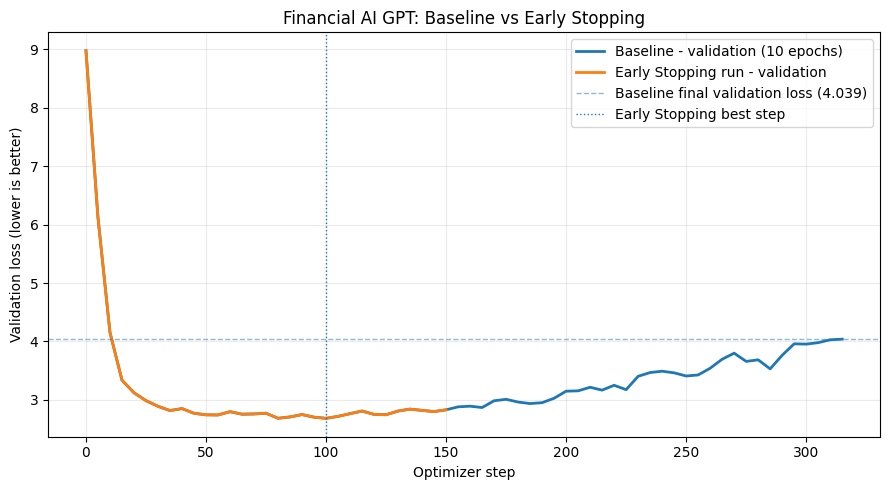


[비교 요약]
기존 10에포크 최저 검증 손실: 2.683
기존 10에포크 최종 검증 손실: 4.039
새 실험 중단 시점 검증 손실: 2.8293
새 실험 최적 모델 검증 손실: 2.6831


In [14]:
import pandas as pd
import matplotlib.pyplot as plt

baseline_history = [{'epoch': 1, 'step': 0, 'training_loss': 9.006, 'validation_loss': 8.978}, {'epoch': 1, 'step': 5, 'training_loss': 6.067, 'validation_loss': 6.121}, {'epoch': 1, 'step': 10, 'training_loss': 3.935, 'validation_loss': 4.154}, {'epoch': 1, 'step': 15, 'training_loss': 3.221, 'validation_loss': 3.337}, {'epoch': 1, 'step': 20, 'training_loss': 2.926, 'validation_loss': 3.121}, {'epoch': 1, 'step': 25, 'training_loss': 2.682, 'validation_loss': 2.986}, {'epoch': 1, 'step': 30, 'training_loss': 2.564, 'validation_loss': 2.889}, {'epoch': 2, 'step': 35, 'training_loss': 2.45, 'validation_loss': 2.816}, {'epoch': 2, 'step': 40, 'training_loss': 2.432, 'validation_loss': 2.85}, {'epoch': 2, 'step': 45, 'training_loss': 2.558, 'validation_loss': 2.77}, {'epoch': 2, 'step': 50, 'training_loss': 2.393, 'validation_loss': 2.743}, {'epoch': 2, 'step': 55, 'training_loss': 2.372, 'validation_loss': 2.741}, {'epoch': 2, 'step': 60, 'training_loss': 2.491, 'validation_loss': 2.797}, {'epoch': 3, 'step': 65, 'training_loss': 2.289, 'validation_loss': 2.754}, {'epoch': 3, 'step': 70, 'training_loss': 2.381, 'validation_loss': 2.758}, {'epoch': 3, 'step': 75, 'training_loss': 2.384, 'validation_loss': 2.771}, {'epoch': 3, 'step': 80, 'training_loss': 2.303, 'validation_loss': 2.684}, {'epoch': 3, 'step': 85, 'training_loss': 2.281, 'validation_loss': 2.707}, {'epoch': 3, 'step': 90, 'training_loss': 2.157, 'validation_loss': 2.748}, {'epoch': 3, 'step': 95, 'training_loss': 2.225, 'validation_loss': 2.703}, {'epoch': 4, 'step': 100, 'training_loss': 2.193, 'validation_loss': 2.683}, {'epoch': 4, 'step': 105, 'training_loss': 2.096, 'validation_loss': 2.717}, {'epoch': 4, 'step': 110, 'training_loss': 2.082, 'validation_loss': 2.763}, {'epoch': 4, 'step': 115, 'training_loss': 2.222, 'validation_loss': 2.808}, {'epoch': 4, 'step': 120, 'training_loss': 2.058, 'validation_loss': 2.751}, {'epoch': 4, 'step': 125, 'training_loss': 2.081, 'validation_loss': 2.745}, {'epoch': 5, 'step': 130, 'training_loss': 2.086, 'validation_loss': 2.808}, {'epoch': 5, 'step': 135, 'training_loss': 1.946, 'validation_loss': 2.841}, {'epoch': 5, 'step': 140, 'training_loss': 1.83, 'validation_loss': 2.819}, {'epoch': 5, 'step': 145, 'training_loss': 1.804, 'validation_loss': 2.799}, {'epoch': 5, 'step': 150, 'training_loss': 1.934, 'validation_loss': 2.829}, {'epoch': 5, 'step': 155, 'training_loss': 1.917, 'validation_loss': 2.88}, {'epoch': 6, 'step': 160, 'training_loss': 1.829, 'validation_loss': 2.891}, {'epoch': 6, 'step': 165, 'training_loss': 1.682, 'validation_loss': 2.868}, {'epoch': 6, 'step': 170, 'training_loss': 1.659, 'validation_loss': 2.984}, {'epoch': 6, 'step': 175, 'training_loss': 1.691, 'validation_loss': 3.009}, {'epoch': 6, 'step': 180, 'training_loss': 1.598, 'validation_loss': 2.962}, {'epoch': 6, 'step': 185, 'training_loss': 1.551, 'validation_loss': 2.936}, {'epoch': 6, 'step': 190, 'training_loss': 1.595, 'validation_loss': 2.951}, {'epoch': 7, 'step': 195, 'training_loss': 1.369, 'validation_loss': 3.027}, {'epoch': 7, 'step': 200, 'training_loss': 1.315, 'validation_loss': 3.148}, {'epoch': 7, 'step': 205, 'training_loss': 1.265, 'validation_loss': 3.154}, {'epoch': 7, 'step': 210, 'training_loss': 1.262, 'validation_loss': 3.215}, {'epoch': 7, 'step': 215, 'training_loss': 1.264, 'validation_loss': 3.166}, {'epoch': 7, 'step': 220, 'training_loss': 1.256, 'validation_loss': 3.249}, {'epoch': 8, 'step': 225, 'training_loss': 1.252, 'validation_loss': 3.174}, {'epoch': 8, 'step': 230, 'training_loss': 1.196, 'validation_loss': 3.403}, {'epoch': 8, 'step': 235, 'training_loss': 1.007, 'validation_loss': 3.467}, {'epoch': 8, 'step': 240, 'training_loss': 0.961, 'validation_loss': 3.49}, {'epoch': 8, 'step': 245, 'training_loss': 0.944, 'validation_loss': 3.462}, {'epoch': 8, 'step': 250, 'training_loss': 0.964, 'validation_loss': 3.408}, {'epoch': 8, 'step': 255, 'training_loss': 0.905, 'validation_loss': 3.426}, {'epoch': 9, 'step': 260, 'training_loss': 0.847, 'validation_loss': 3.541}, {'epoch': 9, 'step': 265, 'training_loss': 0.82, 'validation_loss': 3.695}, {'epoch': 9, 'step': 270, 'training_loss': 1.031, 'validation_loss': 3.799}, {'epoch': 9, 'step': 275, 'training_loss': 0.817, 'validation_loss': 3.658}, {'epoch': 9, 'step': 280, 'training_loss': 0.719, 'validation_loss': 3.685}, {'epoch': 9, 'step': 285, 'training_loss': 0.711, 'validation_loss': 3.53}, {'epoch': 10, 'step': 290, 'training_loss': 0.647, 'validation_loss': 3.763}, {'epoch': 10, 'step': 295, 'training_loss': 0.665, 'validation_loss': 3.959}, {'epoch': 10, 'step': 300, 'training_loss': 0.581, 'validation_loss': 3.954}, {'epoch': 10, 'step': 305, 'training_loss': 0.582, 'validation_loss': 3.979}, {'epoch': 10, 'step': 310, 'training_loss': 0.515, 'validation_loss': 4.028}, {'epoch': 10, 'step': 315, 'training_loss': 0.553, 'validation_loss': 4.039}]

baseline_df = pd.DataFrame(baseline_history)
es_df = pd.DataFrame(es_history)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(baseline_df['step'], baseline_df['validation_loss'],
        label='Baseline - validation (10 epochs)', linewidth=2)
ax.plot(es_df['step'], es_df['validation_loss'],
        label='Early Stopping run - validation', linewidth=2)
ax.axhline(4.039, ls='--', lw=1, alpha=.5,
           label='Baseline final validation loss (4.039)')
ax.axvline(es_summary['best_step'], ls=':', lw=1,
           label='Early Stopping best step')
ax.set_xlabel('Optimizer step')
ax.set_ylabel('Validation loss (lower is better)')
ax.set_title('Financial AI GPT: Baseline vs Early Stopping')
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig('early_stopping_comparison.png', dpi=160)
plt.show()

print('\n[비교 요약]')
print('기존 10에포크 최저 검증 손실:', baseline_df['validation_loss'].min())
print('기존 10에포크 최종 검증 손실:', baseline_df.iloc[-1]['validation_loss'])
print('새 실험 중단 시점 검증 손실:', round(es_summary['stopped_validation_loss'], 4))
print('새 실험 최적 모델 검증 손실:', round(es_summary['restored_validation_loss'], 4))


## 6. 텍스트 생성 비교 (보조 관찰)

동일한 **최적 모델 가중치**로 영어 프롬프트·한국어 프롬프트를 각각 생성해 보기. 프롬프트만 바꾸는 실험이므로 결과 차이를 Early Stopping 효과로 해석하지 않음.

In [15]:
def sample_from_prompt(model, tokenizer, prompt, device, max_new_tokens=45):
    model.eval()
    ids = torch.tensor([tokenizer.encode(prompt)], dtype=torch.long, device=device)
    with torch.no_grad():
        ids_out = generate_text_simple(
            model, ids, max_new_tokens=max_new_tokens,
            context_size=GPT_CONFIG_124M['context_length']
        )
    return tokenizer.decode(ids_out[0].tolist())

prompt_results = {}
for label, prompt in [
    ('english', 'Artificial intelligence in the financial sector'),
    ('korean', '금융 분야에서 인공지능의 활용은')
]:
    result = sample_from_prompt(model_es, tokenizer, prompt, device)
    prompt_results[label] = result
    print(f'[{label}]\n{result}\n')


[english]
Artificial intelligence in the financial sector을 정를 가에성의 있� 있성을 있� 있용에

[korean]
금융 분야에서 인공지능의 활용은에성의 자에성이 금� 이는 있� 적에성을



## 7. 결과 저장 및 다운로드

- `early_stopping_comparison.png` : 그래프
- `early_stopping_history.csv` : 5-step 평가별 새 실험 손실 기록
- `baseline_loss_history.csv` : 기존 제출 노트북에서 추출한 10에포크 손실 기록
- `early_stopping_summary.json` : 비교 지표
- `prompt_samples.json` : 생성 문장 예시
- `best_gpt_early_stopping.pth` : 최적 모델 가중치(큰 파일, GitHub에는 업로드하지 않음)

> **주의:** `early_stopping_results.zip`에는 **모델 가중치 및 저작권이 있는 학습 텍스트를 포함하지 않음**. 후속 실습에 체크포인트가 필요하면 `.pth`는 별도 다운로드 또는 개인 Drive에 저장.

In [16]:
from zipfile import ZipFile, ZIP_DEFLATED

es_df.to_csv('early_stopping_history.csv', index=False, encoding='utf-8-sig')
baseline_df.to_csv('baseline_loss_history.csv', index=False, encoding='utf-8-sig')
with open('early_stopping_summary.json', 'w', encoding='utf-8') as fp:
    json.dump(es_summary, fp, ensure_ascii=False, indent=2)
with open('prompt_samples.json', 'w', encoding='utf-8') as fp:
    json.dump(prompt_results, fp, ensure_ascii=False, indent=2)

result_files = [
    'early_stopping_comparison.png',
    'early_stopping_history.csv',
    'baseline_loss_history.csv',
    'early_stopping_summary.json',
    'prompt_samples.json'
]
with ZipFile('early_stopping_results.zip', 'w', compression=ZIP_DEFLATED) as zf:
    for fn in result_files:
        zf.write(fn)

print('실험 결과 저장 완료: early_stopping_results.zip')
print('별도 보관할 체크포인트:', es_summary['checkpoint_path'])

try:
    from google.colab import files
    files.download('early_stopping_results.zip')
except ImportError:
    print('로컬 환경에서는 현재 폴더의 ZIP을 사용하세요.')

실험 결과 저장 완료: early_stopping_results.zip
별도 보관할 체크포인트: best_gpt_early_stopping.pth


## 8. 해석 가이드 — 결과를 확인하고 문장 완성하기

- 조기 종료 발생 여부: `early_stopping_summary.json`의 `stopped_early` 확인
- 최적 모델: `best_epoch`, `best_step`, `restored_validation_loss` 확인
- 비교: 기존 10에포크 최종 검증 손실 `4.039` 대비 새 실험의 최적 검증 손실 비교
- **주의:** 새 실험의 수치는 실행 전에는 알 수 없음. 손실 개선이 있더라도 자연스러운 한국어 생성까지 보장하지 않음
- **제출 보고서에는:** 실험 조건 → Early Stopping 규칙 → 실제 수치 표 → 비교 그래프 → 한계(단일 검증셋, 재현성, 소량 한국어 데이터) 순서로 추가
- **GitHub에는:** 기존 baseline 노트북 + 본 실험 노트북 + 손실 그래프·요약·가공된 CSV를 반영. 학습 데이터 원문과 `.pth`, 학번 등 개인정보는 제외